In [ ]:
import os, re, sys, shutil, warnings
warnings.filterwarnings("ignore")
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
import sklearn
from sklearn.base import BaseEstimator, TransformerMixin, clone
from sklearn.model_selection import train_test_split, KFold, StratifiedKFold, GridSearchCV
from sklearn.compose import ColumnTransformer, TransformedTargetRegressor
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler, PolynomialFeatures, TargetEncoder
from sklearn.impute import SimpleImputer
from sklearn.decomposition import PCA
from sklearn.metrics import (mean_absolute_error, mean_squared_error, r2_score, accuracy_score,
                             precision_score, recall_score, f1_score, roc_auc_score, roc_curve,
                             ConfusionMatrixDisplay)
from sklearn.linear_model import LinearRegression, Ridge, Lasso, LogisticRegression, Perceptron
from sklearn.tree import DecisionTreeRegressor, DecisionTreeClassifier
from sklearn.neighbors import KNeighborsRegressor, KNeighborsClassifier
from sklearn.svm import SVR, SVC
from sklearn.ensemble import RandomForestRegressor
from sklearn.neural_network import MLPRegressor, MLPClassifier
from sklearn.naive_bayes import GaussianNB

RANDOM_STATE = 42
THRESHOLD = 45          # affordability threshold, lakh rupees
QUICK_RUN = False       # True = fast test run (numbers NOT for the paper)
N_FOLDS = 3 if QUICK_RUN else 5
os.makedirs("outputs", exist_ok=True)
print("Python", sys.version.split()[0], "| scikit-learn", sklearn.__version__,
      "| pandas", pd.__version__, "| NumPy", np.__version__)

Python 3.13.18 | scikit-learn 1.6.1 | pandas 2.2.3 | NumPy 2.1.3


## Step 1 — Upload the CSV
Download `Bengaluru_House_Data.csv` from the Kaggle link first, then run this cell and choose the file.
**PAPER:** Section 3.1 → fills **[N₀]** and **[P₀]**.
**SEND ME:** the printed shape.

In [ ]:
try:
    from google.colab import files
    up = files.upload()
    file_name = [n for n in up if n.lower().endswith(".csv")][0]
except ImportError:
    file_name = "Bengaluru_House_Data.csv"      # running outside Colab
raw = pd.read_csv(file_name)
raw.columns = raw.columns.str.strip()
N0, P0 = raw.shape
print("Original dataset:", N0, "records,", P0, "variables")
display(raw.head())

Saving Bengaluru_House_Data.csv to Bengaluru_House_Data.csv
Original dataset: 13320 records, 9 variables


,area_type,availability,location,size,society,total_sqft,bath,balcony,price
0,Super built-up Area,19-Dec,Electronic City Phase II,2 BHK,Coomee,1056,2.0,1.0,39.07
1,Plot Area,Ready To Move,Chikka Tirupathi,4 Bedroom,Theanmp,2600,5.0,3.0,120.00
2,Built-up Area,Ready To Move,Uttarahalli,3 BHK,NaN,1440,2.0,3.0,62.00
3,Super built-up Area,Ready To Move,Lingadheeranahalli,3 BHK,Soiewre,1521,3.0,1.0,95.00
4,Super built-up Area,Ready To Move,Kothanur,2 BHK,NaN,1200,2.0,1.0,51.00


## Step 2 — Variables table and missing values
**PAPER:** Table 1 and Figure 1 (Section 3.1–3.2).
**SEND ME:** screenshot of the table + the bar chart.

,Type,Missing %,Unique
area_type,object,0.0,4
availability,object,0.0,81
location,object,0.0,1305
size,object,0.1,31
society,object,41.3,2688
total_sqft,object,0.0,2117
bath,float64,0.5,19
balcony,float64,4.6,4
price,float64,0.0,1994


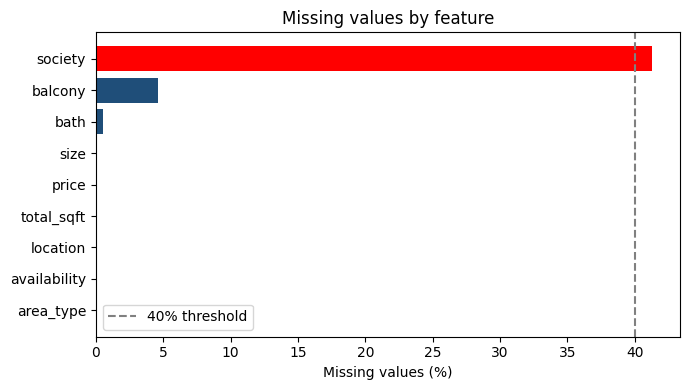

Dropped for >40% missing: ['society']


In [ ]:
table1 = pd.DataFrame({"Type": raw.dtypes.astype(str),
                       "Missing %": (raw.isna().mean()*100).round(1),
                       "Unique": raw.nunique()})
display(table1)
table1.to_csv("outputs/table1_variables.csv")

m = table1["Missing %"].sort_values()
plt.figure(figsize=(7,4))
plt.barh(m.index, m.values, color=["red" if v > 40 else "#1f4e79" for v in m.values])
plt.axvline(40, ls="--", color="gray", label="40% threshold")
plt.xlabel("Missing values (%)"); plt.legend(); plt.title("Missing values by feature")
plt.tight_layout(); plt.savefig("outputs/fig1_missing.png", dpi=300); plt.show()
high_missing = table1.index[table1["Missing %"] > 40].tolist()
print("Dropped for >40% missing:", high_missing)

## Step 3 — Cleaning, unit conversion, screening rules, outliers
**PAPER:** Section 3.2–3.3 → fills **[N_missing]**, **[N_rules]**, **[N_final]** and the outlier percentages.
**SEND ME:** all the printed lines.

In [ ]:
UNIT = {"sq. feet":1.0, "sq. meter":10.7639, "sq. yards":9.0, "acres":43560.0,
        "cents":435.56, "guntha":1089.0, "perch":272.25, "grounds":2400.0}

def parse_area(v):
    if pd.isna(v): return np.nan
    s = str(v).strip().lower().replace(",", "")
    m = re.fullmatch(r"\s*(\d+(?:\.\d+)?)\s*[-–]\s*(\d+(?:\.\d+)?)\s*", s)       # range -> midpoint
    if m: return (float(m.group(1)) + float(m.group(2))) / 2
    m = re.fullmatch(r"\s*(\d+(?:\.\d+)?)\s*([a-z. ]+?)\s*", s)                   # number + unit
    if m:
        u = m.group(2).strip()
        return float(m.group(1)) * UNIT[u] if u in UNIT else np.nan
    try: return float(s)
    except ValueError: return np.nan

d = raw.drop(columns=high_missing).copy()
d["sqft"] = d["total_sqft"].apply(parse_area)
d["bhk"] = pd.to_numeric(d["size"].astype(str).str.extract(r"(\d+)")[0], errors="coerce")
d["ready"] = (d["availability"].astype(str).str.strip().str.lower() == "ready to move").astype(int)
d["location"] = d["location"].astype("string").str.strip()
d["area_type"] = d["area_type"].astype("string").str.strip()
for c in ["bath", "balcony", "price"]:
    d[c] = pd.to_numeric(d[c], errors="coerce")

n0 = len(d)
d = d.dropna(subset=["sqft", "bhk", "price", "location"])
d = d[(d.sqft > 0) & (d.bhk > 0) & (d.price > 0)]
N_missing = n0 - len(d)
n1 = len(d); d = d.drop_duplicates(subset=["area_type","location","sqft","bhk","bath","balcony","price","ready"])
N_dupes = n1 - len(d)

def iqr_pct(s):
    s = s.dropna(); q1, q3 = s.quantile([.25, .75]); i = q3 - q1
    return round(((s < q1 - 1.5*i) | (s > q3 + 1.5*i)).mean()*100, 2)
cols = ["sqft", "bhk", "bath", "balcony", "price"]
out_before = {c: iqr_pct(d[c]) for c in cols}

n2 = len(d)
d = d[d.sqft / d.bhk >= 300]                      # rule 1: at least 300 sq ft per BHK
d = d[~(d.bath > d.bhk + 2)]                      # rule 2: baths not more than BHK + 2
N_rules = n2 - len(d)

d["ppsf"] = d.price * 1e5 / d.sqft                # used ONLY to remove outliers, never as a predictor
lp = np.log(d.ppsf)                               # IQR rule on log scale so BOTH tails are caught
q1, q3 = lp.quantile([.25, .75]); i = q3 - q1
n3 = len(d); d = d[(lp >= q1 - 1.5*i) & (lp <= q3 + 1.5*i)]
N_outliers = n3 - len(d)
out_after = {c: iqr_pct(d[c]) for c in cols}

final_df = d.reset_index(drop=True)
N_final = len(final_df)
print(f"Original: {N0}  | removed missing/unparseable: {N_missing} | duplicates: {N_dupes}")
print(f"Removed by screening rules: {N_rules} | removed as price-per-sqft IQR outliers: {N_outliers}")
print(f"FINAL modelling sample: {N_final}")
print("IQR outlier % before screening:", out_before)
print("IQR outlier % after  screening:", out_after)
print("Largest area kept (sq ft):", round(final_df.sqft.max()), "| largest price kept (lakh):", round(final_df.price.max()))
print(final_df[["sqft","price"]].describe().round(1))

Original: 13320  | removed missing/unparseable: 17 | duplicates: 659
Removed by screening rules: 747 | removed as price-per-sqft IQR outliers: 529
FINAL modelling sample: 11368
IQR outlier % before screening: {'sqft': np.float64(9.13), 'bhk': np.float64(6.64), 'bath': np.float64(8.18), 'balcony': np.float64(0.0), 'price': np.float64(9.56)}
IQR outlier % after  screening: {'sqft': np.float64(8.52), 'bhk': np.float64(2.63), 'bath': np.float64(4.76), 'balcony': np.float64(0.0), 'price': np.float64(8.13)}
Largest area kept (sq ft): 30400 | largest price kept (lakh): 2100
          sqft    price
count  11368.0  11368.0
mean    1549.6     96.2
std      948.6     88.9
min      300.0     10.0
25%     1110.0     49.0
50%     1300.0     69.0
75%     1690.0    110.0
max    30400.0   2100.0


## Step 4 — Exploratory plots
**PAPER:** Figure 2 (two panels) and Figure 3 (correlation matrix), Section 3.3.
**SEND ME:** screenshots of both figures.

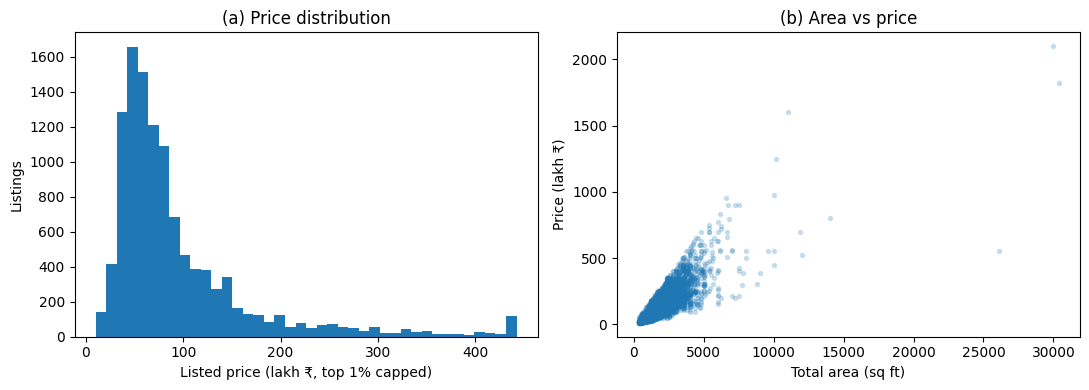

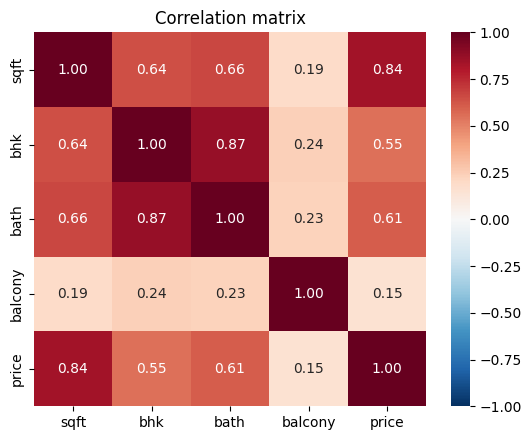

In [ ]:
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].hist(final_df.price.clip(upper=final_df.price.quantile(.99)), bins=40)
ax[0].set_xlabel("Listed price (lakh ₹, top 1% capped)"); ax[0].set_ylabel("Listings"); ax[0].set_title("(a) Price distribution")
ax[1].scatter(final_df.sqft, final_df.price, alpha=.2, s=8)
ax[1].set_xlabel("Total area (sq ft)"); ax[1].set_ylabel("Price (lakh ₹)"); ax[1].set_title("(b) Area vs price")
plt.tight_layout(); plt.savefig("outputs/fig2_eda.png", dpi=300); plt.show()

plt.figure(figsize=(5.5, 4.5))
sns.heatmap(final_df[["sqft","bhk","bath","balcony","price"]].corr(), annot=True, fmt=".2f", cmap="RdBu_r", vmin=-1, vmax=1)
plt.title("Correlation matrix"); plt.tight_layout(); plt.savefig("outputs/fig3_corr.png", dpi=300); plt.show()

## Step 5 — Train/test split and preprocessing
**PAPER:** Section 5 → fills **[N_train]** and **[N_test]**. All preprocessing is fitted on training data only.
**SEND ME:** the printed counts.

In [ ]:
final_df["affordable"] = (final_df.price <= THRESHOLD).astype(int)
num_cols, bin_cols, cat_cols = ["sqft", "bhk", "bath", "balcony"], ["ready"], ["location", "area_type"]
X = final_df[num_cols + bin_cols + cat_cols]
y = final_df["price"]; y_cls = final_df["affordable"]
X_train, X_test, y_train, y_test, yc_train, yc_test = train_test_split(
    X, y, y_cls, test_size=0.20, random_state=RANDOM_STATE, stratify=y_cls)
N_train, N_test = len(X_train), len(X_test)
print("N_train =", N_train, "| N_test =", N_test)
print(f"Affordable share (<= Rs {THRESHOLD} lakh): train {yc_train.mean():.3f}, test {yc_test.mean():.3f}")

class Winsorizer(BaseEstimator, TransformerMixin):
    def __init__(self, q=99): self.q = q
    def fit(self, X, y=None): self.hi_ = np.nanpercentile(X, self.q, axis=0); return self
    def transform(self, X): return np.minimum(X, self.hi_)

def make_pre(loc_enc="onehot", poly=False):
    steps = [("imp", SimpleImputer(strategy="median")), ("win", Winsorizer(99)), ("sc", StandardScaler())]
    if poly: steps.append(("poly", PolynomialFeatures(2, include_bias=False)))
    ohe = lambda: OneHotEncoder(handle_unknown="infrequent_if_exist", min_frequency=10, sparse_output=False)
    loc = (ohe() if loc_enc == "onehot"
           else TargetEncoder(target_type="continuous", cv=5, random_state=RANDOM_STATE))
    return ColumnTransformer([("num", Pipeline(steps), num_cols), ("bin", "passthrough", bin_cols),
                              ("loc", loc, ["location"]), ("area", ohe(), ["area_type"])], sparse_threshold=0)

def make_reg(model, enc="onehot", poly=False):
    return TransformedTargetRegressor(regressor=Pipeline([("pre", make_pre(enc, poly)), ("model", model)]),
                                      func=np.log1p, inverse_func=np.expm1)

def reg_metrics(yt, p):
    return {"MAE": mean_absolute_error(yt, p), "RMSE": float(np.sqrt(mean_squared_error(yt, p))), "R2": r2_score(yt, p)}

N_train = 9094 | N_test = 2274
Affordable share (<= Rs 45 lakh): train 0.205, test 0.205


## Step 6 — Nine regression models + baseline (the main task)
**PAPER:** Table 2 (hyperparameters), Table 3 (results), Figure 6, Section 6.1. Includes **Polynomial Regression**.
**SEND ME:** screenshot of Table 2, Table 3, and the observed-vs-predicted plot. (This is the slowest cell.)

done: Linear Regression (OLS)
done: Ridge
done: Lasso
done: Polynomial Regression (deg 2)
done: Decision Tree
done: k-NN
done: SVR (RBF)
done: Random Forest
done: MLP (64-32)


,Model,Grid searched,Selected
0,Linear Regression (OLS),-,-
1,Ridge,"{'alpha': [1, 10, 100]}",{'alpha': 1}
2,Lasso,"{'alpha': [0.001, 0.01, 0.1]}",{'alpha': 0.1}
3,Polynomial Regression (deg 2),-,-
4,Decision Tree,"{'max_depth': [8, 12, 16], 'min_samples_leaf':...","{'max_depth': 8, 'min_samples_leaf': 5}"
5,k-NN,"{'n_neighbors': [5, 15, 31], 'weights': ['unif...","{'n_neighbors': 15, 'weights': 'distance'}"
6,SVR (RBF),"{'C': [10, 100], 'epsilon': [0.05, 0.2]}","{'C': 10, 'epsilon': 0.2}"
7,Random Forest,"{'min_samples_leaf': [2, 5]}",{'min_samples_leaf': 2}
8,MLP (64-32),"{'alpha': [0.0001, 0.01]}",{'alpha': 0.01}


,Model,MAE,RMSE,R2,CV-RMSE
0,Linear Regression (OLS),25.568,54.782,0.632,53.488
1,Ridge,25.572,54.865,0.631,53.485
2,Lasso,29.214,54.232,0.639,55.322
3,Polynomial Regression (deg 2),22.526,48.066,0.717,47.885
4,Decision Tree,25.050,50.562,0.686,49.354
5,k-NN,22.559,48.614,0.710,49.294
6,SVR (RBF),22.448,46.119,0.739,46.502
7,Random Forest,22.731,47.506,0.723,46.989
8,MLP (64-32),21.634,45.722,0.744,47.011
9,Baseline (median Rs/sqft),30.072,58.604,0.579,NaN


Best regression model (lowest test RMSE): MLP (64-32)
Baseline RMSE: 58.6 | best model RMSE: 45.72


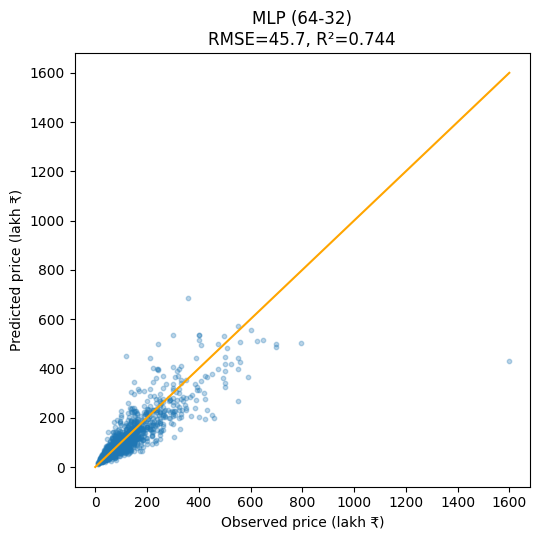

In [ ]:
cv_reg = KFold(N_FOLDS, shuffle=True, random_state=RANDOM_STATE)
P = "regressor__model__"
n_trees = 50 if QUICK_RUN else 200
reg_specs = {   # name: (model, grid, poly?)
 "Linear Regression (OLS)": (LinearRegression(), {}, False),
 "Ridge":  (Ridge(), {P+"alpha": [1, 10, 100]}, False),
 "Lasso":  (Lasso(max_iter=10000), {P+"alpha": [0.001, 0.01, 0.1]}, False),
 "Polynomial Regression (deg 2)": (LinearRegression(), {}, True),
 "Decision Tree": (DecisionTreeRegressor(random_state=RANDOM_STATE),
                   {P+"max_depth": [8, 12, 16], P+"min_samples_leaf": [5, 10]}, False),
 "k-NN": (KNeighborsRegressor(), {P+"n_neighbors": [5, 15, 31], P+"weights": ["uniform", "distance"]}, False),
 "SVR (RBF)": (SVR(kernel="rbf"), {P+"C": [10, 100], P+"epsilon": [0.05, 0.2]}, False),
 "Random Forest": (RandomForestRegressor(n_estimators=n_trees, random_state=RANDOM_STATE),
                   {P+"min_samples_leaf": [2, 5]}, False),
 "MLP (64-32)": (MLPRegressor(hidden_layer_sizes=(64, 32), max_iter=500, early_stopping=True, random_state=RANDOM_STATE),
                 {P+"alpha": [1e-4, 1e-2]}, False),
}
fitted_reg, rows, grid_rows = {}, [], []
for name, (mdl, grid, poly) in reg_specs.items():
    gs = GridSearchCV(make_reg(mdl, "onehot", poly), grid, cv=cv_reg,
                      scoring="neg_root_mean_squared_error", n_jobs=-1).fit(X_train, y_train)
    pred = gs.predict(X_test)
    fitted_reg[name] = gs.best_estimator_
    rows.append({"Model": name, **reg_metrics(y_test, pred), "CV-RMSE": -gs.best_score_})
    grid_rows.append({"Model": name,
                      "Grid searched": {k.split("__")[-1]: v for k, v in grid.items()} or "-",
                      "Selected": {k.split("__")[-1]: v for k, v in gs.best_params_.items()} or "-"})
    print(f"done: {name}")

# Baseline: floor area x median Rs-per-sqft from TRAINING data
med_ppsf = (y_train * 1e5 / X_train["sqft"]).median()
base_pred = (X_test["sqft"] * med_ppsf / 1e5)
rows.append({"Model": "Baseline (median Rs/sqft)", **reg_metrics(y_test, base_pred), "CV-RMSE": np.nan})

results = pd.DataFrame(rows)
table2 = pd.DataFrame(grid_rows)
model_rows = results[~results.Model.str.startswith("Baseline")]
best_reg_name = model_rows.loc[model_rows.RMSE.idxmin(), "Model"]
best_reg = fitted_reg[best_reg_name]; best_pred = best_reg.predict(X_test)
display(table2); display(results.round(3))
results.to_csv("outputs/table3_regression.csv", index=False); table2.astype(str).to_csv("outputs/table2_hyperparameters.csv", index=False)
print("Best regression model (lowest test RMSE):", best_reg_name)
print("Baseline RMSE:", round(results.iloc[-1].RMSE, 2), "| best model RMSE:", round(model_rows.RMSE.min(), 2))

plt.figure(figsize=(5.5, 5.5)); plt.scatter(y_test, best_pred, alpha=.3, s=10)
u = max(y_test.max(), best_pred.max()); plt.plot([0, u], [0, u], "orange")
r = reg_metrics(y_test, best_pred)
plt.xlabel("Observed price (lakh ₹)"); plt.ylabel("Predicted price (lakh ₹)")
plt.title(f"{best_reg_name}\nRMSE={r['RMSE']:.1f}, R²={r['R2']:.3f}")
plt.tight_layout(); plt.savefig("outputs/fig6_obs_vs_pred.png", dpi=300); plt.show()

## Step 7 — One-hot vs target-mean encoding
**PAPER:** new table 'Table 3b' in Section 3.3 / 6.1 (brief requires one-hot / target-mean encoding). Target-mean uses out-of-fold means (no leakage).
**SEND ME:** screenshot of the table.

In [ ]:
enc_rows = []
for name, mdl in [("Linear Regression", LinearRegression()), ("k-NN (k=15)", KNeighborsRegressor(15))]:
    for enc, label in [("onehot", "One-hot"), ("target", "Target-mean (out-of-fold)")]:
        p = make_reg(clone(mdl), enc).fit(X_train, y_train).predict(X_test)
        enc_rows.append({"Model": name, "Encoding": label, **reg_metrics(y_test, p)})
table3b = pd.DataFrame(enc_rows); display(table3b.round(3))
table3b.to_csv("outputs/table3b_encoding.csv", index=False)

,Model,Encoding,MAE,RMSE,R2
0,Linear Regression,One-hot,25.568,54.782,0.632
1,Linear Regression,Target-mean (out-of-fold),26.397,62.674,0.518
2,k-NN (k=15),One-hot,23.555,46.904,0.730
3,k-NN (k=15),Target-mean (out-of-fold),22.829,47.355,0.725


## Step 8 — Seven classifiers (supporting task: below ₹45 lakh or not)
**PAPER:** Table 4, Figure 7 (ROC), confusion-matrix figure, Section 6.2.
**SEND ME:** screenshot of Table 4, the ROC plot, and the confusion matrix.

done: Logistic regression
done: Gaussian NB
done: Decision tree
done: k-NN
done: Perceptron
done: SVM (RBF)
done: MLP (64-32)


,Model,Acc,Prec,Recall,F1,AUC,CV-F1
0,Logistic regression,0.838,0.568,0.873,0.688,0.930,0.680
1,Gaussian NB,0.376,0.241,0.955,0.385,0.600,0.385
2,Decision tree,0.824,0.544,0.854,0.665,0.902,0.657
3,k-NN,0.868,0.698,0.624,0.659,0.882,0.663
4,Perceptron,0.863,0.701,0.579,0.635,0.915,0.584
5,SVM (RBF),0.843,0.578,0.858,0.691,0.928,0.698
6,MLP (64-32),0.886,0.759,0.650,0.701,0.934,0.686
7,Baseline,0.847,0.834,0.313,0.456,0.899,NaN


Best classifier by cross-validation F1: SVM (RBF)


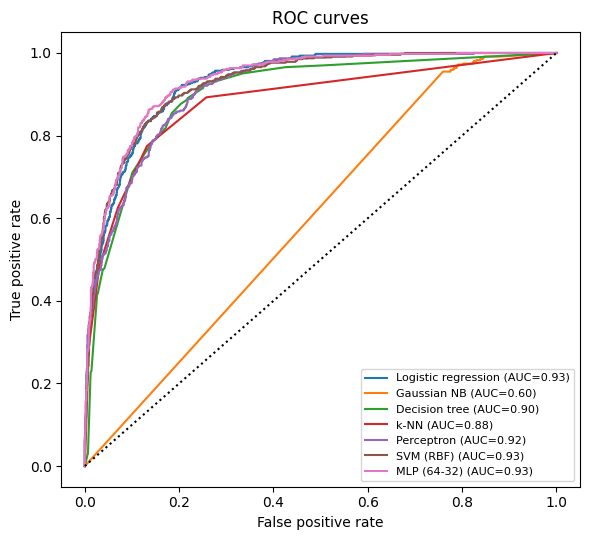

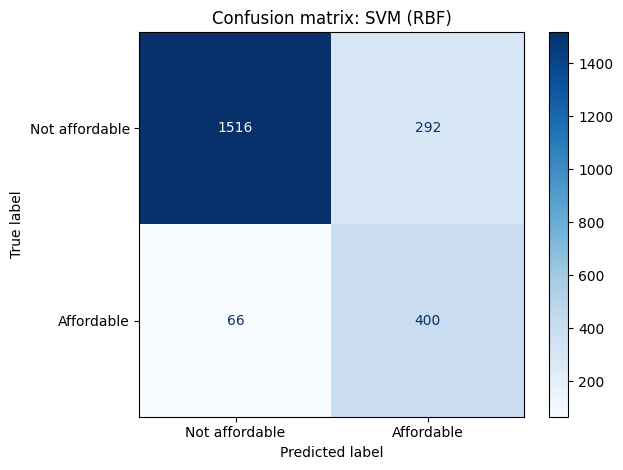

In [ ]:
cv_cls = StratifiedKFold(N_FOLDS, shuffle=True, random_state=RANDOM_STATE)
Q = "model__"
cls_specs = {
 "Logistic regression": (LogisticRegression(max_iter=3000), {Q+"C": [0.1, 1, 10], Q+"class_weight": [None, "balanced"]}),
 "Gaussian NB": (GaussianNB(), {}),
 "Decision tree": (DecisionTreeClassifier(random_state=RANDOM_STATE), {Q+"max_depth": [8, 12], Q+"class_weight": [None, "balanced"]}),
 "k-NN": (KNeighborsClassifier(), {Q+"n_neighbors": [5, 15, 31]}),
 "Perceptron": (Perceptron(random_state=RANDOM_STATE), {Q+"alpha": [1e-4, 1e-2]}),
 "SVM (RBF)": (SVC(kernel="rbf"), {Q+"C": [1, 10], Q+"class_weight": [None, "balanced"]}),
 "MLP (64-32)": (MLPClassifier(hidden_layer_sizes=(64, 32), max_iter=500, early_stopping=True, random_state=RANDOM_STATE),
                 {Q+"alpha": [1e-4, 1e-2]}),
}
def score_of(m, Xs):
    return m.predict_proba(Xs)[:, 1] if hasattr(m, "predict_proba") else m.decision_function(Xs)
def cls_metrics(yt, yp, sc):
    return {"Acc": accuracy_score(yt, yp), "Prec": precision_score(yt, yp, zero_division=0),
            "Recall": recall_score(yt, yp), "F1": f1_score(yt, yp), "AUC": roc_auc_score(yt, sc)}

fitted_cls, crow, curves = {}, [], {}
for name, (mdl, grid) in cls_specs.items():
    gs = GridSearchCV(Pipeline([("pre", make_pre("onehot")), ("model", mdl)]), grid, cv=cv_cls,
                      scoring="f1", n_jobs=-1).fit(X_train, yc_train)
    m = gs.best_estimator_; sc = score_of(m, X_test)
    fitted_cls[name] = m; curves[name] = roc_curve(yc_test, sc)[:2] + (roc_auc_score(yc_test, sc),)
    crow.append({"Model": name, **cls_metrics(yc_test, m.predict(X_test), sc), "CV-F1": gs.best_score_})
    print("done:", name)
bsc = -base_pred.values
crow.append({"Model": "Baseline", **cls_metrics(yc_test, (base_pred <= THRESHOLD).astype(int), bsc), "CV-F1": np.nan})
table4 = pd.DataFrame(crow); display(table4.round(3)); table4.to_csv("outputs/table4_classification.csv", index=False)
best_cls_name = table4.iloc[:-1].sort_values("CV-F1", ascending=False).iloc[0]["Model"]
print("Best classifier by cross-validation F1:", best_cls_name)

plt.figure(figsize=(6, 5.5))
for n, (fpr, tpr, a) in curves.items(): plt.plot(fpr, tpr, label=f"{n} (AUC={a:.2f})")
plt.plot([0, 1], [0, 1], "k:"); plt.xlabel("False positive rate"); plt.ylabel("True positive rate")
plt.legend(fontsize=8, loc="lower right"); plt.title("ROC curves"); plt.tight_layout()
plt.savefig("outputs/fig7_roc.png", dpi=300); plt.show()

ConfusionMatrixDisplay.from_predictions(yc_test, fitted_cls[best_cls_name].predict(X_test),
        display_labels=["Not affordable", "Affordable"], cmap="Blues")
plt.title(f"Confusion matrix: {best_cls_name}"); plt.tight_layout()
plt.savefig("outputs/fig_confusion_matrix.png", dpi=300); plt.show()

## Step 9 — PCA (components needed + with/without comparison)
**PAPER:** Figure 4, Table 5, Section 6.3 → fills **k90** and **k95** (numbers of components, not %).
**SEND ME:** k90, k95, the Figure 4 plot, and Table 5.

Total features after preprocessing: 199 | k90 = 18 components | k95 = 63 components


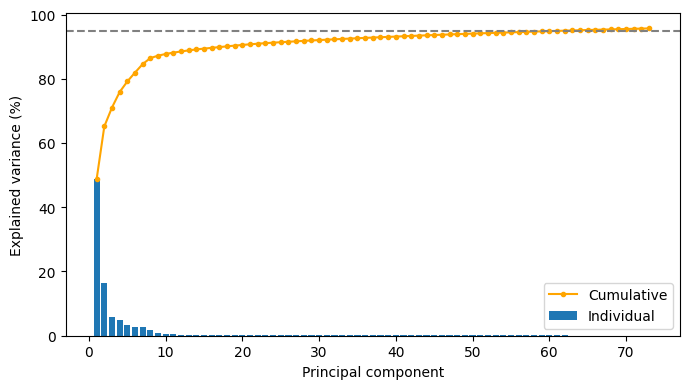

,Setting,MAE,RMSE,R2
0,"OLS, all features",25.568,54.782,0.632
1,"OLS, PCA 95%",28.003,59.426,0.567
2,"k-NN (k=15), all features",23.555,46.904,0.730
3,"k-NN (k=15), PCA 95%",24.297,47.384,0.725


In [ ]:
Z = make_pre("onehot").fit(X_train).transform(X_train)
pca = PCA(random_state=RANDOM_STATE).fit(Z)
cum = np.cumsum(pca.explained_variance_ratio_) * 100
k90, k95 = int(np.argmax(cum >= 90) + 1), int(np.argmax(cum >= 95) + 1)
print(f"Total features after preprocessing: {Z.shape[1]} | k90 = {k90} components | k95 = {k95} components")

nshow = min(max(k95 + 10, 40), len(cum))
plt.figure(figsize=(7, 4))
plt.bar(range(1, nshow + 1), pca.explained_variance_ratio_[:nshow] * 100, label="Individual")
plt.plot(range(1, nshow + 1), cum[:nshow], "o-", color="orange", ms=3, label="Cumulative")
plt.axhline(95, ls="--", color="gray"); plt.xlabel("Principal component"); plt.ylabel("Explained variance (%)")
plt.legend(); plt.tight_layout(); plt.savefig("outputs/fig4_pca.png", dpi=300); plt.show()

def pca_reg(model, use_pca):
    steps = [("pre", make_pre("onehot"))] + ([("pca", PCA(0.95, random_state=RANDOM_STATE))] if use_pca else []) + [("model", model)]
    return TransformedTargetRegressor(regressor=Pipeline(steps), func=np.log1p, inverse_func=np.expm1)
prow = []
for name, mdl in [("OLS", LinearRegression()), ("k-NN (k=15)", KNeighborsRegressor(15))]:
    for use, lab in [(False, "all features"), (True, "PCA 95%")]:
        p = pca_reg(clone(mdl), use).fit(X_train, y_train).predict(X_test)
        prow.append({"Setting": f"{name}, {lab}", **reg_metrics(y_test, p)})
table5 = pd.DataFrame(prow); display(table5.round(3)); table5.to_csv("outputs/table5_pca.csv", index=False)

## Step 10 — Robustness: location groups, BHK groups, per-location error
**PAPER:** Section 6.3 results + Appendix Table A1 (replaces the 'Insert tableA1…' sentence).
**SEND ME:** the three tables.

In [ ]:
loc_counts = X_train.location.value_counts()
def loc_group(l):
    n = loc_counts.get(l, 0)
    return "unseen" if n == 0 else ("rare (1-9 train records)" if n < 10 else "frequent (>=10)")
rmse = lambda a, b: float(np.sqrt(np.mean((np.asarray(a) - np.asarray(b)) ** 2)))
te = pd.DataFrame({"location": X_test.location.values, "bhk": X_test.bhk.values, "y": y_test.values,
                   "pred": best_pred, "base": base_pred.values})
te["loc_group"] = te.location.map(loc_group)
te["bhk_group"] = np.where(te.bhk > 5, "6+", te.bhk.astype(int).astype(str))

def summarise(col):
    return pd.DataFrame([{"Group": g, "n_test": len(s), "MAE": mean_absolute_error(s.y, s.pred),
                          "RMSE": rmse(s.y, s.pred), "Baseline RMSE": rmse(s.y, s.base)}
                         for g, s in te.groupby(col)])
rob_loc, rob_bhk = summarise("loc_group"), summarise("bhk_group")
display(rob_loc.round(2)); display(rob_bhk.round(2))
rob_loc.to_csv("outputs/robust_location_groups.csv", index=False); rob_bhk.to_csv("outputs/robust_bhk.csv", index=False)

top20 = te.location.value_counts().head(20).index
a1 = pd.DataFrame([{"loc": l, "n_train": int(loc_counts.get(l, 0)), "n_test": len(s), "mean_price": s.y.mean(),
                    "RMSE_model": rmse(s.y, s.pred), "RMSE_baseline": rmse(s.y, s.base),
                    "worse_than_baseline": rmse(s.y, s.pred) > rmse(s.y, s.base)}
                   for l, s in te[te.location.isin(top20)].groupby("location")]).sort_values("n_test", ascending=False)
display(a1.round(1)); a1.to_csv("outputs/tableA1_per_location.csv", index=False)

,Group,n_test,MAE,RMSE,Baseline RMSE
0,frequent (>=10),1697,17.62,32.43,49.86
1,rare (1-9 train records),495,29.69,48.29,65.63
2,unseen,82,56.12,148.77,133.40


,Group,n_test,MAE,RMSE,Baseline RMSE
0,1,118,9.78,13.59,16.49
1,2,1007,11.33,18.93,22.70
2,3,873,20.99,34.00,49.18
3,4,227,65.25,113.85,143.64
4,5,25,62.09,83.72,108.89
5,6+,24,80.64,100.84,83.57


,loc,n_train,n_test,mean_price,RMSE_model,RMSE_baseline,worse_than_baseline
18,Whitefield,399,104,140.8,52.9,92.1,False
15,Sarjapur Road,285,77,109.0,34.7,42.5,False
4,Electronic City,214,62,57.5,23.5,20.6,True
10,Kanakpura Road,175,51,77.2,16.6,20.7,False
16,Thanisandra,188,42,73.2,25.2,22.4,True
11,Marathahalli,123,40,98.9,23.2,35.0,False
19,Yelahanka,160,39,81.3,21.9,22.8,False
13,Raja Rajeshwari Nagar,123,32,54.7,8.8,16.8,False
17,Uttarahalli,119,28,53.9,12.1,14.8,False
8,Hebbal,120,27,140.8,40.7,96.4,False


## Step 11 — Affordable localities (the 'map' deliverable)
**PAPER:** new Section 6.4, Figures 8 and 9.
**SEND ME:** both figures + the top-10 / bottom-10 tables.

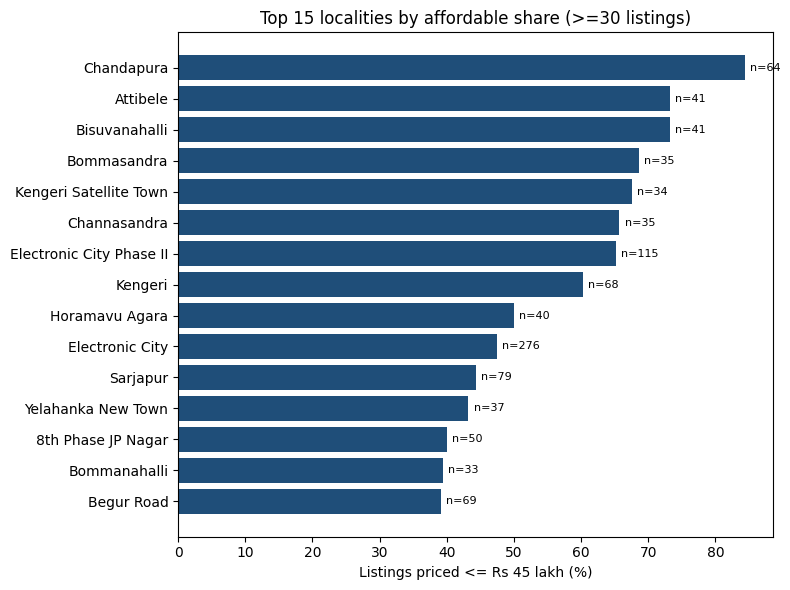

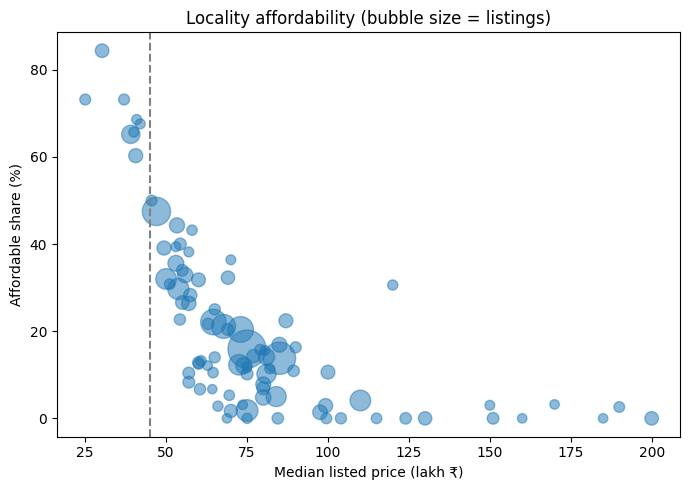

Overall share priced <= 45 lakh: 20.5%
MOST affordable localities:


,listings,median_price,affordable_share_pct
location,,,
Chandapura,64,30.2175,84.4
Attibele,41,25.0000,73.2
Bisuvanahalli,41,37.0000,73.2
Bommasandra,35,40.8900,68.6
Kengeri Satellite Town,34,42.0000,67.6
Channasandra,35,40.0000,65.7
Electronic City Phase II,115,39.0700,65.2
Kengeri,68,40.6000,60.3
Horamavu Agara,40,45.5000,50.0


LEAST affordable localities:


,listings,median_price,affordable_share_pct
location,,,
Bhoganhalli,40,99.5,0.0
Green Glen Layout,39,115.0,0.0
Koramangala,62,130.0,0.0
Indira Nagar,31,160.0,0.0
Hegde Nagar,46,124.0,0.0
Lakshminarayana Pura,36,75.0,0.0
Rajaji Nagar,63,200.0,0.0
Kundalahalli,43,104.0,0.0
Thigalarapalya,47,151.0,0.0


In [ ]:
g = (final_df.groupby("location").agg(listings=("price", "size"), affordable_share=("affordable", "mean"),
                                       median_price=("price", "median"))
     .query("listings >= 30").sort_values("affordable_share", ascending=False))
g["affordable_share_pct"] = (g.affordable_share * 100).round(1)
g.to_csv("outputs/affordable_localities.csv")
top = g.head(15)
fig, ax = plt.subplots(figsize=(8, 6))
ax.barh(top.index[::-1], top.affordable_share_pct[::-1], color="#1f4e79")
for i, (s, n) in enumerate(zip(top.affordable_share_pct[::-1], top.listings[::-1])):
    ax.text(s + 0.8, i, f"n={n}", va="center", fontsize=8)
ax.set_xlabel(f"Listings priced <= Rs {THRESHOLD} lakh (%)"); ax.set_title("Top 15 localities by affordable share (>=30 listings)")
plt.tight_layout(); plt.savefig("outputs/fig8_affordable_localities.png", dpi=300); plt.show()

plt.figure(figsize=(7, 5))
plt.scatter(g.median_price, g.affordable_share_pct, s=g.listings * 1.5, alpha=.5)
plt.axvline(THRESHOLD, ls="--", color="gray"); plt.xlabel("Median listed price (lakh ₹)"); plt.ylabel("Affordable share (%)")
plt.title("Locality affordability (bubble size = listings)"); plt.tight_layout()
plt.savefig("outputs/fig9_bubble.png", dpi=300); plt.show()
print("Overall share priced <= 45 lakh: %.1f%%" % (final_df.affordable.mean() * 100))
print("MOST affordable localities:"); display(g.head(10)[["listings", "median_price", "affordable_share_pct"]])
print("LEAST affordable localities:"); display(g.tail(10)[["listings", "median_price", "affordable_share_pct"]])

## Step 12 — Summary of every number for the paper + download
**SEND ME:** everything printed here (it fills all remaining placeholders), then download the zip.

In [ ]:
summary = f'''N0 (original records)           : {N0}
P0 (original variables)         : {P0}
Dropped for >40% missing        : {high_missing}
N_missing (missing/unparseable) : {N_missing}
Duplicates removed              : {N_dupes}
N_rules (screening rules)       : {N_rules}
Price-per-sqft IQR outliers     : {N_outliers}
N_final                         : {N_final}
N_train / N_test                : {N_train} / {N_test}
IQR outlier % before / after    : {out_before} / {out_after}
k90 / k95 components            : {k90} / {k95}
Median Rs/sqft (train)          : {med_ppsf:.0f}
Best regression model           : {best_reg_name}
Best classifier (by CV F1)      : {best_cls_name}
Python {sys.version.split()[0]}, scikit-learn {sklearn.__version__}, pandas {pd.__version__}, NumPy {np.__version__}
Random seed                     : {RANDOM_STATE}'''
print(summary); open("outputs/summary_numbers.txt", "w").write(summary)
shutil.make_archive("bengaluru_outputs", "zip", "outputs")
try:
    from google.colab import files; files.download("bengaluru_outputs.zip")
except ImportError:
    pass

N0 (original records)           : 13320
P0 (original variables)         : 9
Dropped for >40% missing        : ['society']
N_missing (missing/unparseable) : 17
Duplicates removed              : 659
N_rules (screening rules)       : 747
Price-per-sqft IQR outliers     : 529
N_final                         : 11368
N_train / N_test                : 9094 / 2274
IQR outlier % before / after    : {'sqft': np.float64(9.13), 'bhk': np.float64(6.64), 'bath': np.float64(8.18), 'balcony': np.float64(0.0), 'price': np.float64(9.56)} / {'sqft': np.float64(8.52), 'bhk': np.float64(2.63), 'bath': np.float64(4.76), 'balcony': np.float64(0.0), 'price': np.float64(8.13)}
k90 / k95 components            : 18 / 63
Median Rs/sqft (train)          : 5259
Best regression model           : MLP (64-32)
Best classifier (by CV F1)      : SVM (RBF)
Python 3.13.18, scikit-learn 1.6.1, pandas 2.2.3, NumPy 2.1.3
Random seed                     : 42


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>